In [2]:
import pandas as pd

df = pd.read_csv("Intensivregister_updated.csv", sep=";")
print(df)


            date  care_group  reporting_units  current_covid_cases  \
0     10/02/2023  ERWACHSENE             1271                  655   
1     10/02/2023        NICU              194                    2   
2     10/02/2023        PICU              158                   12   
3     11/02/2023  ERWACHSENE             1271                  677   
4     11/02/2023        NICU              194                    4   
...          ...         ...              ...                  ...   
3283  08/02/2026        NICU              148                    1   
3284  08/02/2026        PICU              116                    2   
3285  09/02/2026  ERWACHSENE              804                   54   
3286  09/02/2026        NICU              148                    1   
3287  09/02/2026        PICU              117                    2   

      icu_beds_occupied  icu_beds_available  material_constraints  \
0                 18527                2537                     1   
1                  13

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# ---------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------
df = pd.read_csv("Intensivregister_updated.csv", sep=";")

# Clean column names (remove trailing spaces)
df.columns = df.columns.str.strip()

# ---------------------------------------------------------
# 2. Convert European decimal commas to dots
# ---------------------------------------------------------
cols_to_fix = ["utilization_rate", "staff_constraint_rate"]

for col in cols_to_fix:
    df[col] = df[col].astype(str).str.replace(",", ".")
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ---------------------------------------------------------
# 3. Select indicators
# ---------------------------------------------------------
util_col = "utilization_rate"
staff_col = "staff_constraint_rate"

X = df[[util_col, staff_col]].copy()

# ---------------------------------------------------------
# 4. Standardize variables (z-scores)
# ---------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------------------------------------
# 5. K-means clustering
# ---------------------------------------------------------
k = 4
kmeans = KMeans(n_clusters=k, n_init=50, random_state=42)
df["cluster"] = kmeans.fit_predict(X_scaled)

# ---------------------------------------------------------
# 6. Cluster summaries in original units
# ---------------------------------------------------------
cluster_summary = (
    df.groupby("cluster")[[util_col, staff_col]]
      .agg(["mean", "median", "std", "min", "max"])
)

print("\nCluster characterization in original units:")
print(cluster_summary)

# ---------------------------------------------------------
# 7. Optional: assign regime labels
# ---------------------------------------------------------
regime_labels = {
    0: "baseline",
    1: "capacity pressure",
    2: "staff pressure",
    3: "compound strain"
}

df["regime"] = df["cluster"].map(regime_labels)

print("\nSample of labeled data:")
print(df[["cluster", "regime", util_col, staff_col]].head())



Cluster characterization in original units:
        utilization_rate                              staff_constraint_rate  \
                    mean median       std   min   max                  mean   
cluster                                                                       
0               0.629625   0.63  0.035450  0.53  0.72              0.187179   
1               0.846920   0.85  0.019824  0.77  0.90              0.270657   
2               0.856037   0.86  0.031194  0.71  0.90              0.401422   
3               0.671744   0.68  0.031835  0.57  0.76              0.309249   

                                      
        median       std   min   max  
cluster                               
0         0.19  0.033745  0.10  0.26  
1         0.29  0.037967  0.21  0.33  
2         0.39  0.044223  0.34  0.50  
3         0.30  0.040388  0.24  0.42  

Sample of labeled data:
   cluster           regime  utilization_rate  staff_constraint_rate
0        2   staff pressure       

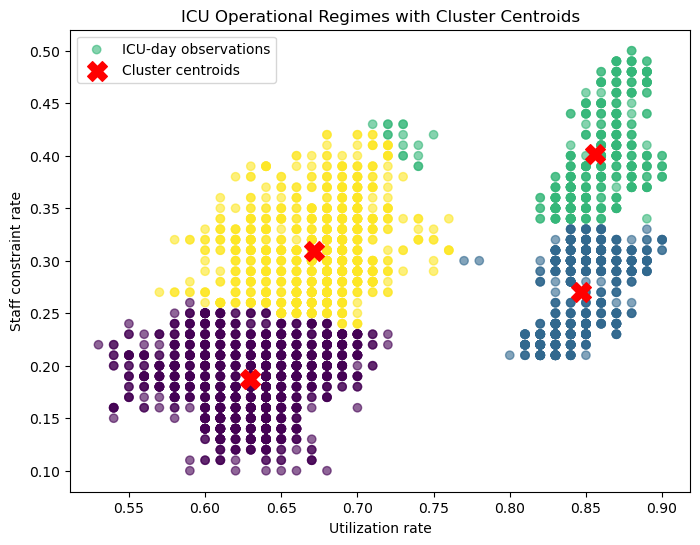

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Get centroids in original units
centroids_scaled = kmeans.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

plt.figure(figsize=(8,6))

# Scatter points
plt.scatter(
    df["utilization_rate"],
    df["staff_constraint_rate"],
    c=df["cluster"],
    cmap="viridis",
    alpha=0.6,
    label="ICU-day observations"
)

# Centroids
plt.scatter(
    centroids[:,0],
    centroids[:,1],
    c="red",
    s=200,
    marker="X",
    label="Cluster centroids"
)

plt.xlabel("Utilization rate")
plt.ylabel("Staff constraint rate")
plt.title("ICU Operational Regimes with Cluster Centroids")
plt.legend()
plt.show()


In [17]:
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
df = df.sort_values("date")

# Convert decimals if needed
for col in ["staff_constraint_rate", "space_constraint_rate"]:
    df[col] = df[col].astype(str).str.replace(",", ".")
    df[col] = pd.to_numeric(df[col], errors="coerce")


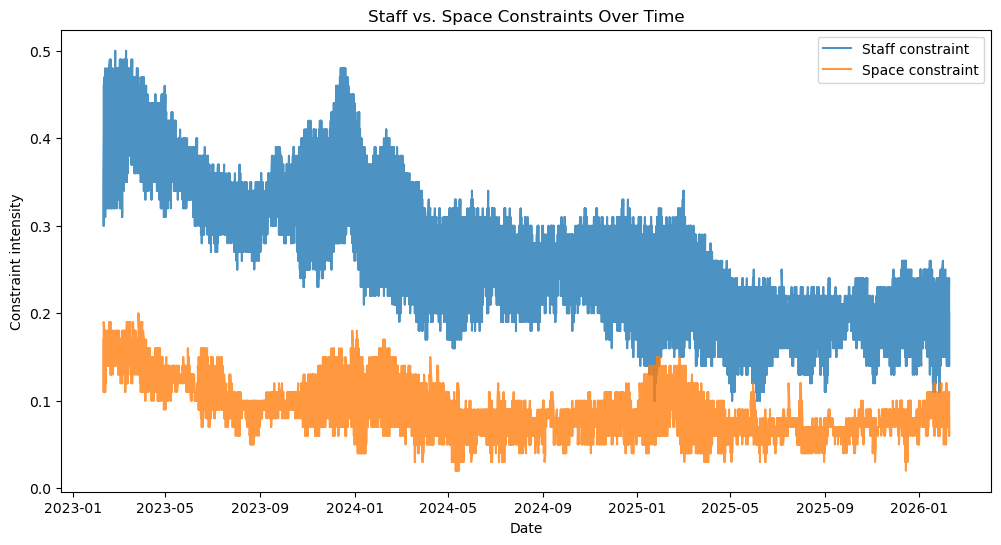

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(df["date"], df["staff_constraint_rate"], label="Staff constraint", alpha=0.8)
plt.plot(df["date"], df["space_constraint_rate"], label="Space constraint", alpha=0.8)

plt.title("Staff vs. Space Constraints Over Time")
plt.xlabel("Date")
plt.ylabel("Constraint intensity")
plt.legend()
plt.show()


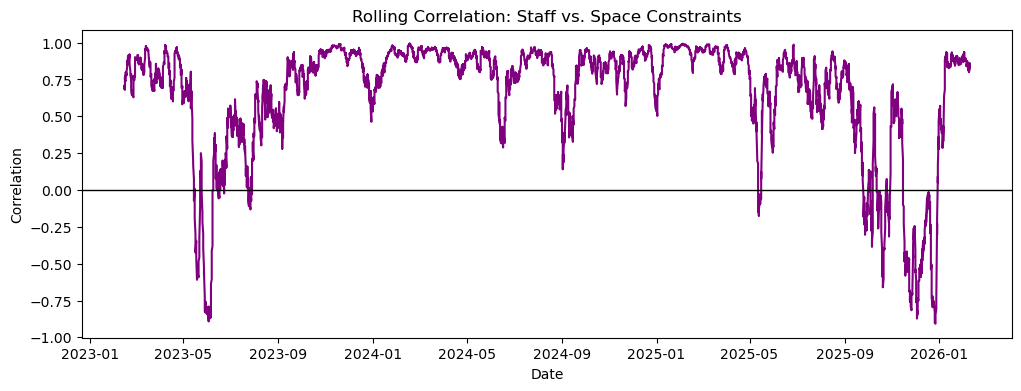

In [21]:
df["rolling_corr"] = (
    df["staff_constraint_rate"]
    .rolling(window=14)   # 14‑day window, adjust as needed
    .corr(df["space_constraint_rate"])
)

plt.figure(figsize=(12,4))
plt.plot(df["date"], df["rolling_corr"], color="purple")
plt.axhline(0, color="black", linewidth=1)

plt.title("Rolling Correlation: Staff vs. Space Constraints")
plt.ylabel("Correlation")
plt.xlabel("Date")
plt.show()


#+1 → they move together perfectly
#0 → no relationship
#–1 → they move in opposite directions
#Periods of high correlation → constraints rise/fall together
#Periods of low correlation → constraints behave independently

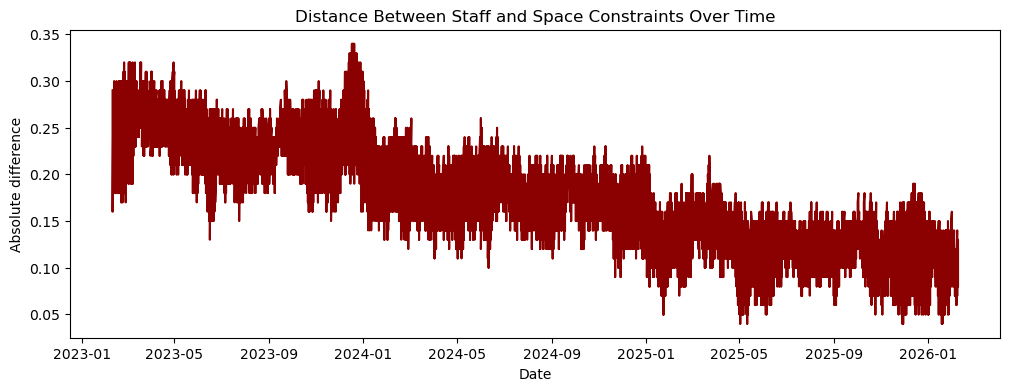

In [23]:
df["distance"] = abs(df["staff_constraint_rate"] - df["space_constraint_rate"])

plt.figure(figsize=(12,4))
plt.plot(df["date"], df["distance"], color="darkred")
plt.title("Distance Between Staff and Space Constraints Over Time")
plt.ylabel("Absolute difference")
plt.xlabel("Date")
plt.show()
#Low distance → constraints are similar in magnitude
# High distance → one constraint dominates (e.g., staff shortage without space shortage)

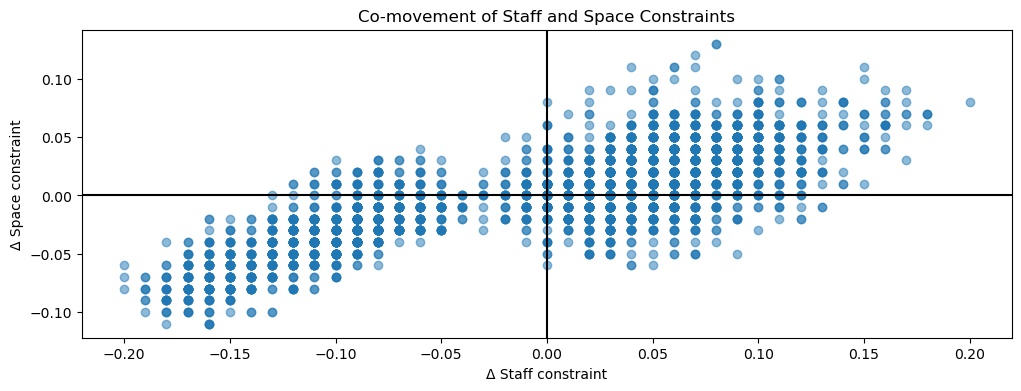

In [25]:
df["staff_diff"] = df["staff_constraint_rate"].diff()
df["space_diff"] = df["space_constraint_rate"].diff()

plt.figure(figsize=(12,4))
plt.scatter(df["staff_diff"], df["space_diff"], alpha=0.5)
plt.axhline(0, color="black")
plt.axvline(0, color="black")

plt.title("Co‑movement of Staff and Space Constraints")
plt.xlabel("Δ Staff constraint")
plt.ylabel("Δ Space constraint")
plt.show()


# Points in upper‑right → both constraints increasing together
# Points in lower‑left → both decreasing
# Points in upper‑left / lower‑right → moving in opposite directions

In [8]:
import pandas as pd
import numpy as np
from scipy.stats import zscore

# Load dataset
df = pd.read_csv("Intensivregister_updated.csv", sep=";")

# Remove COVID-related columns
df = df.loc[:, ~df.columns.str.contains("covid", case=False)]

# Define care group column (adjust if needed)
care_column = "care_group"   # change if your column name differs

# Loop through each care group separately
for group in df[care_column].unique():
    
    print(f"\n===== {group.upper()} =====")
    
    df_group = df[df[care_column] == group]
    
    # Select numeric columns
    numeric_cols = df_group.select_dtypes(include=["int64", "float64"]).columns
    
    # Compute Z-scores within group
    z_scores = df_group[numeric_cols].apply(zscore)
    
    threshold = 3
    outlier_mask = np.abs(z_scores) > threshold
    
    # Count outliers per column
    print("Outliers per column (|Z| > 3):")
    print(outlier_mask.sum())
    
    # Total rows with outliers
    total_outliers = outlier_mask.any(axis=1).sum()
    print("Total rows with at least one outlier:", total_outliers)
    
    # Optional: show first few outlier rows
    df_outliers = df_group[outlier_mask.any(axis=1)]
    print("\nFirst few outlier rows:")
    print(df_outliers.head())


===== ERWACHSENE =====
Outliers per column (|Z| > 3):
reporting_units          0
icu_beds_occupied        0
icu_beds_available       0
material_constraints    11
staff_constraints        0
space_constraints        8
total_icu_capacity       0
dtype: int64
Total rows with at least one outlier: 19

First few outlier rows:
          date  care_group  reporting_units  icu_beds_occupied  \
12  14/02/2023  ERWACHSENE             1272              18589   
21  17/02/2023  ERWACHSENE             1274              18657   
24  18/02/2023  ERWACHSENE             1276              18395   
27  19/02/2023  ERWACHSENE             1274              18044   
90  12/03/2023  ERWACHSENE             1259              17877   

    icu_beds_available  material_constraints  staff_constraints  \
12                2506                     1                596   
21                2350                     1                617   
24                2488                     2                620   
27          

In [10]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("Intensivregister_updated.csv", sep=";")

# Ensure numeric conversion (important if commas are used)
numeric_cols = [
    "icu_beds_occupied",
    "icu_beds_available",
    "total_icu_capacity"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check logical consistency
df["calculated_capacity"] = df["icu_beds_occupied"] + df["icu_beds_available"]

# Identify inconsistencies
inconsistencies = df[df["calculated_capacity"] != df["total_icu_capacity"]]

# Print results
print("Total rows checked:", len(df))
print("Rows with inconsistencies:", len(inconsistencies))

if len(inconsistencies) > 0:
    print("\nInconsistent rows:")
    print(inconsistencies[[
        "date",
        "care_group",
        "icu_beds_occupied",
        "icu_beds_available",
        "total_icu_capacity",
        "calculated_capacity"
    ]])
else:
    print("\nNo logical inconsistencies detected.")

Total rows checked: 3288
Rows with inconsistencies: 0

No logical inconsistencies detected.


In [13]:
import pandas as pd
import numpy as np
from scipy import stats

# Load the dataset
df = pd.read_csv('Intensivregister_updated.csv')

# Ensure date column is datetime format
df['date'] = pd.to_datetime(df['date'])

# Sort by date
df = df.sort_values('date').reset_index(drop=True)

# ============================================================================
# Step 1: Calculate Constraint Rates
# ============================================================================

# Staff constraint rate: staff-related operational restrictions / number of reporting ICU units
df['staff_constraint_rate'] = df['einschraenkung_personal'] / df['anzahl_meldebereiche']

# Space constraint rate: space-related operational restrictions / number of reporting ICU units
df['space_constraint_rate'] = df['einschraenkung_raum'] / df['anzahl_meldebereiche']

# Material constraint rate: material-related operational restrictions / number of reporting ICU units
df['material_constraint_rate'] = df['einschraenkung_material'] / df['anzahl_meldebereiche']

# ICU utilization rate: occupied beds / (occupied + available beds)
df['utilization_rate'] = df['intensivbetten_belegt'] / (df['intensivbetten_belegt'] + df['intensivbetten_frei'])

# Capacity slack: available beds / total beds
df['capacity_slack'] = df['intensivbetten_frei'] / (df['intensivbetten_belegt'] + df['intensivbetten_frei'])

# ============================================================================
# Step 2: Calculate Z-Scores for Each Constraint Rate
# ============================================================================

# Z-score for staff constraint rate
df['zscore_staff_constraint'] = stats.zscore(df['staff_constraint_rate'], nan_policy='omit')

# Z-score for space constraint rate
df['zscore_space_constraint'] = stats.zscore(df['space_constraint_rate'], nan_policy='omit')

# Z-score for material constraint rate
df['zscore_material_constraint'] = stats.zscore(df['material_constraint_rate'], nan_policy='omit')

# Z-score for utilization rate (optional, useful for analysis)
df['zscore_utilization'] = stats.zscore(df['utilization_rate'], nan_policy='omit')

# Z-score for capacity slack (optional, useful for analysis)
df['zscore_slack'] = stats.zscore(df['capacity_slack'], nan_policy='omit')

# ============================================================================
# Step 3: Display Summary Statistics
# ============================================================================

print("=" * 80)
print("CONSTRAINT RATES - DESCRIPTIVE STATISTICS")
print("=" * 80)
print("\nStaff Constraint Rate:")
print(df['staff_constraint_rate'].describe())
print("\nSpace Constraint Rate:")
print(df['space_constraint_rate'].describe())
print("\nMaterial Constraint Rate:")
print(df['material_constraint_rate'].describe())

print("\n" + "=" * 80)
print("Z-SCORES - DESCRIPTIVE STATISTICS")
print("=" * 80)
print("\nZ-Score Staff Constraint:")
print(df['zscore_staff_constraint'].describe())
print("\nZ-Score Space Constraint:")
print(df['zscore_space_constraint'].describe())
print("\nZ-Score Material Constraint:")
print(df['zscore_material_constraint'].describe())

# ============================================================================
# Step 4: Save Enhanced Dataset
# ============================================================================

# Save to CSV
df.to_csv('Intensivregister_with_zscore_constraints.csv', index=False)
print("\n" + "=" * 80)
print("✓ Enhanced dataset saved to: Intensivregister_with_zscore_constraints.csv")
print("=" * 80)

# Display sample of new columns
print("\nSample of new columns (first 10 rows):")
print(df[[
    'date',
    'staff_constraint_rate',
    'space_constraint_rate', 
    'material_constraint_rate',
    'utilization_rate',
    'capacity_slack',
    'zscore_staff_constraint',
    'zscore_space_constraint',
    'zscore_material_constraint',
    'zscore_utilization'
]].head(10))

print("\n" + "=" * 80)
print("Column Descriptions:")
print("=" * 80)
print("""
Constraint Rates (scaled 0-1):
- staff_constraint_rate: Staff shortage restrictions / reporting units
- space_constraint_rate: Space shortage restrictions / reporting units
- material_constraint_rate: Material shortage restrictions / reporting units

Utilization Metrics:
- utilization_rate: Occupied beds / Total beds (0-1 scale)
- capacity_slack: Available beds / Total beds (0-1 scale)

Z-Scores (standardized, mean=0, std=1):
- zscore_staff_constraint: Standardized staff constraint rate
- zscore_space_constraint: Standardized space constraint rate
- zscore_material_constraint: Standardized material constraint rate
- zscore_utilization: Standardized utilization rate
- zscore_slack: Standardized capacity slack

Interpretation of Z-Scores:
- Z-score > 0: Above average constraint/utilization
- Z-score < 0: Below average constraint/utilization
- |Z-score| > 2: Extreme values (top/bottom 5%)
- |Z-score| > 3: Very extreme values (top/bottom 0.3%)
""")

ParserError: Error tokenizing data. C error: Expected 5 fields in line 3, saw 6


In [15]:
import pandas as pd
import numpy as np
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# LOAD DATA WITH CORRECT PARSING
# ============================================================================

print("Loading Intensivregister_updated.csv...")
print("  - Delimiter: semicolon (;)")
print("  - Decimal: comma (,)")
print("  - Encoding: UTF-8 with BOM")

# Read CSV with German format (semicolon delimiter, comma as decimal)
df = pd.read_csv(
    'Intensivregister_updated.csv',
    sep=';',           # Use semicolon as delimiter
    decimal=',',       # Use comma as decimal separator
    encoding='utf-8-sig'  # Handle UTF-8 BOM
)

print(f"✓ Loaded {len(df)} records\n")

# ============================================================================
# INSPECT THE DATA
# ============================================================================

print("="*80)
print("COLUMN NAMES AND FIRST FEW ROWS")
print("="*80)
print("\nColumns in dataset:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i}. {col}")

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

# ============================================================================
# DATA PREPARATION
# ============================================================================

# Convert date column to datetime
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
    df = df.sort_values('date').reset_index(drop=True)
    print(f"\n✓ Date range: {df['date'].min()} to {df['date'].max()}")

# ============================================================================
# CALCULATE Z-SCORES FOR CONSTRAINT RATES
# ============================================================================

print("\n" + "="*80)
print("CALCULATING Z-SCORES FOR CONSTRAINT RATES")
print("="*80)

# The constraint rates appear to already be calculated in the CSV:
# - staff_constraint_rate
# - material_constraint_rate
# - space_constraint_rate

# However, let's verify and recalculate them to ensure accuracy
# Based on methodology: constraint_rate = constraints / reporting_units

if all(col in df.columns for col in ['staff_constraints', 'reporting_units']):
    print("\n✓ Recalculating constraint rates from raw counts:")
    
    # Recalculate staff constraint rate
    df['staff_constraint_rate_calc'] = df['staff_constraints'] / df['reporting_units']
    print(f"  - Staff constraint rate (calculated): {df['staff_constraint_rate_calc'].mean():.4f}")
    
    # Recalculate material constraint rate
    df['material_constraint_rate_calc'] = df['material_constraints'] / df['reporting_units']
    print(f"  - Material constraint rate (calculated): {df['material_constraint_rate_calc'].mean():.4f}")
    
    # Recalculate space constraint rate
    df['space_constraint_rate_calc'] = df['space_constraints'] / df['reporting_units']
    print(f"  - Space constraint rate (calculated): {df['space_constraint_rate_calc'].mean():.4f}")
    
    # Use calculated rates
    staff_col = 'staff_constraint_rate_calc'
    material_col = 'material_constraint_rate_calc'
    space_col = 'space_constraint_rate_calc'
else:
    # Use existing columns from CSV
    print("\n✓ Using constraint rates from CSV:")
    staff_col = 'staff_constraint_rate '  # Note: trailing space in CSV
    material_col = 'material_constraint_rate'
    space_col = 'space_constraint_rate '  # Note: trailing space in CSV
    
    # Clean up whitespace in column names
    df.columns = df.columns.str.strip()

print("\n" + "="*80)
print("CONSTRAINT RATES - SUMMARY STATISTICS")
print("="*80)

# Get actual column names (handle trailing spaces)
constraint_cols = {
    'Staff': [c for c in df.columns if 'staff_constraint_rate' in c][0],
    'Material': [c for c in df.columns if 'material_constraint_rate' in c][0],
    'Space': [c for c in df.columns if 'space_constraint_rate' in c][0]
}

for name, col in constraint_cols.items():
    print(f"\n{name} Constraint Rate ({col}):")
    print(f"  Mean:   {df[col].mean():.4f}")
    print(f"  Std:    {df[col].std():.4f}")
    print(f"  Min:    {df[col].min():.4f}")
    print(f"  Max:    {df[col].max():.4f}")
    print(f"  Count:  {df[col].notna().sum()} non-null values")

# ============================================================================
# CALCULATE Z-SCORES
# ============================================================================

print("\n" + "="*80)
print("CALCULATING Z-SCORES")
print("="*80)

# Staff constraint z-score
df['zscore_staff_constraint'] = stats.zscore(
    df[constraint_cols['Staff']], 
    nan_policy='omit'
)
print(f"✓ Added zscore_staff_constraint")

# Material constraint z-score
df['zscore_material_constraint'] = stats.zscore(
    df[constraint_cols['Material']], 
    nan_policy='omit'
)
print(f"✓ Added zscore_material_constraint")

# Space constraint z-score
df['zscore_space_constraint'] = stats.zscore(
    df[constraint_cols['Space']], 
    nan_policy='omit'
)
print(f"✓ Added zscore_space_constraint")

# Optional: Z-score for utilization rate
if 'utilization_rate' in df.columns:
    df['zscore_utilization'] = stats.zscore(
        df['utilization_rate'], 
        nan_policy='omit'
    )
    print(f"✓ Added zscore_utilization")

# Optional: Z-score for slack rate
if 'slack_rate' in df.columns:
    df['zscore_slack'] = stats.zscore(
        df['slack_rate'], 
        nan_policy='omit'
    )
    print(f"✓ Added zscore_slack")

# ============================================================================
# Z-SCORE VALIDATION
# ============================================================================

print("\n" + "="*80)
print("Z-SCORES - SUMMARY STATISTICS (Validation)")
print("="*80)

zscore_cols = [col for col in df.columns if col.startswith('zscore_')]

for col in zscore_cols:
    print(f"\n{col}:")
    print(f"  Mean: {df[col].mean():.8f} (should ≈ 0)")
    print(f"  Std:  {df[col].std():.8f} (should ≈ 1)")
    print(f"  Min:  {df[col].min():.4f}")
    print(f"  Max:  {df[col].max():.4f}")
    
    # Count extreme values
    extreme_2sd = (np.abs(df[col]) > 2).sum()
    extreme_3sd = (np.abs(df[col]) > 3).sum()
    pct_2sd = (extreme_2sd / len(df)) * 100
    pct_3sd = (extreme_3sd / len(df)) * 100
    print(f"  |z| > 2: {extreme_2sd} observations ({pct_2sd:.2f}%)")
    print(f"  |z| > 3: {extreme_3sd} observations ({pct_3sd:.2f}%)")

# ============================================================================
# BY-GROUP STATISTICS (by care_group)
# ============================================================================

if 'care_group' in df.columns:
    print("\n" + "="*80)
    print("Z-SCORES BY CARE GROUP (ERWACHSENE, PICU, NICU)")
    print("="*80)
    
    for group in df['care_group'].unique():
        print(f"\n{group}:")
        group_data = df[df['care_group'] == group]
        print(f"  Records: {len(group_data)}")
        
        for col in ['zscore_staff_constraint', 'zscore_material_constraint', 'zscore_space_constraint']:
            if col in df.columns:
                mean_z = group_data[col].mean()
                std_z = group_data[col].std()
                print(f"  {col}: mean={mean_z:.4f}, std={std_z:.4f}")

# ============================================================================
# SAVE OUTPUT
# ============================================================================

output_path = 'Intensivregister_with_zscore_constraints.csv'
df.to_csv(output_path, sep=';', decimal=',', index=False, encoding='utf-8-sig')

print("\n" + "="*80)
print(f"✓ SAVED: {output_path}")
print("="*80)

# ============================================================================
# DISPLAY SAMPLE
# ============================================================================

print("\nSample output (first 10 rows):")
sample_cols = ['date', 'care_group', 'reporting_units']
sample_cols.extend(constraint_cols.values())
sample_cols.extend([c for c in df.columns if c.startswith('zscore_')])

# Filter to available columns
sample_cols = [c for c in sample_cols if c in df.columns]

print(df[sample_cols].head(10).to_string())

print("\n" + "="*80)
print("DONE!")
print("="*80)

Loading Intensivregister_updated.csv...
  - Delimiter: semicolon (;)
  - Decimal: comma (,)
  - Encoding: UTF-8 with BOM
✓ Loaded 3288 records

COLUMN NAMES AND FIRST FEW ROWS

Columns in dataset:
  1. date
  2. care_group
  3. reporting_units
  4. current_covid_cases
  5. icu_beds_occupied
  6. icu_beds_available
  7. material_constraints
  8. staff_constraints
  9. space_constraints
  10. total_icu_capacity
  11. utilization_rate
  12. slack_rate
  13. staff_constraint_rate 
  14. material_constraint_rate
  15. space_constraint_rate 

First 5 rows:
         date  care_group  reporting_units  current_covid_cases  \
0  10/02/2023  ERWACHSENE             1271                  655   
1  10/02/2023        NICU              194                    2   
2  10/02/2023        PICU              158                   12   
3  11/02/2023  ERWACHSENE             1271                  677   
4  11/02/2023        NICU              194                    4   

   icu_beds_occupied  icu_beds_available

In [20]:
import pandas as pd

# Load data
df = pd.read_csv("Intensivregister_updated.csv", sep=";")

rate_columns = [
    "slack_rate",
    "staff_constraint_rate",
    "material_constraint_rate",
    "space_constraint_rate"
]

# Force numeric conversion (invalid values → NaN)
for col in rate_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", ".", regex=False)  # handle decimal commas
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Z-score normalization
for col in rate_columns:
    z_col = f"{col}_z"
    df[z_col] = (df[col] - df[col].mean()) / df[col].std(ddof=0)

# Save new file
output_path = "Intensivregister_updated_zscores.csv"
df.to_csv(output_path, sep=";", index=False)

print("Z-score normalization completed and file saved.")

KeyError: 'staff_constraint_rate'

In [27]:
import pandas as pd

# ---------------------------------------------------
# 1. Load data
# ---------------------------------------------------
df = pd.read_csv("Intensivregister_updated.csv", sep=";")

# ---------------------------------------------------
# 2. Standardize column names
# ---------------------------------------------------
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)

# ---------------------------------------------------
# 3. Define rate variables (exact names)
# ---------------------------------------------------
rate_columns = [
    "slack_rate",
    "staff_constraint_rate",
    "material_constraint_rate",
    "space_constraint_rate"
]

# ---------------------------------------------------
# 4. Safety check
# ---------------------------------------------------
missing_cols = [c for c in rate_columns if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing expected columns: {missing_cols}")

# ---------------------------------------------------
# 5. Convert to numeric
# ---------------------------------------------------
for col in rate_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", ".", regex=False)
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ---------------------------------------------------
# 6. Z-score normalization (rounded to 3 decimals)
# ---------------------------------------------------
for col in rate_columns:
    z = (df[col] - df[col].mean()) / df[col].std(ddof=0)
    df[f"{col}_z"] = z.round(3)

# ---------------------------------------------------
# 7. Save new dataset
# ---------------------------------------------------
output_file = "Intensivregister_updated_zscores.csv"
df.to_csv(output_file, sep=";", index=False)

print("Z-score normalization completed (rounded to 3 decimals).")
print(f"File saved as: {output_file}")

Z-score normalization completed (rounded to 3 decimals).
File saved as: Intensivregister_updated_zscores.csv
